# Phân tích cảm xúc bình luận phim IMDB

**24022473 Nguyễn Đức Trung K69A-AI1**

Phân loại bình luận thành **negative (0)** hoặc **positive (1)** bằng LSTM,
so sánh với Logistic Regression, SVM tuyến tính và MLP.

In [ ]:
from pathlib import Path
from collections import Counter
from copy import deepcopy
import hashlib
import html
import importlib.metadata
import json
import os
import platform
import random
import re
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)
import joblib
import torch
from torch import nn

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "artifacts"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything()
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
environment = {
    "python": platform.python_version(), "platform": platform.platform(),
    "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "packages": {p: importlib.metadata.version(p) for p in
                 ["numpy", "pandas", "pyarrow", "scipy", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel"]},
    "seed": SEED,
}
print(json.dumps(environment, ensure_ascii=False, indent=2))
(OUT / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
if DEVICE.type == "cpu":
    print("CPU mode: chạy được nhưng LSTM sẽ chậm hơn GPU.")

## 1. Dữ liệu

Bộ [IMDB của Stanford](https://huggingface.co/datasets/stanfordnlp/imdb)
gồm 50.000 bình luận có nhãn, cân bằng hai lớp. Giữ nguyên 25.000 mẫu test
chính thức; chia phân tầng tập train thành **20.000 mẫu train** và
**5.000 mẫu validation**, với seed 42.

Dữ liệu Parquet được cố định phiên bản và kiểm tra SHA-256 để bảo đảm khả năng tái lập.
Không sử dụng dữ liệu không nhãn đi kèm bộ IMDB.

In [ ]:
REVISION = "e6281661ce1c48d982bc483cf8a173c1bbeb5d31"
EXPECTED_HASHES = {
    "train": "db47d16b5c297cc0dd625e519c81319c24c9149e70e8496de5475f6fa928342c",
    "test": "b52e26e2f872d282ffac460bf9770b25ac6f102cda0e6ca7158df98c94e8b3da",
}
source = {"repository": "stanfordnlp/imdb", "revision": REVISION, "files": {}}
loaded = []
for split in ["train", "test"]:
    url = f"https://huggingface.co/datasets/stanfordnlp/imdb/resolve/{REVISION}/plain_text/{split}-00000-of-00001.parquet"
    path = DATA / f"{split}.parquet"
    if not path.exists():
        partial = path.with_suffix(".part")
        with urllib.request.urlopen(url, timeout=120) as response, partial.open("wb") as target:
            while chunk := response.read(1024 * 1024):
                target.write(chunk)
        partial.replace(path)
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    assert digest == EXPECTED_HASHES[split], f"Checksum mismatch: {path}"
    source["files"][split] = {"url": url, "bytes": path.stat().st_size, "sha256": digest}
    frame = pd.read_parquet(path)
    assert len(frame) == 25_000 and set(frame.label.unique()) == {0, 1}
    frame["id"] = [f"{split}/{i:05d}" for i in range(len(frame))]
    frame["official_split"] = split
    loaded.append(frame)
reviews = pd.concat(loaded, ignore_index=True)
(OUT / "data_source.json").write_text(json.dumps(source, indent=2), encoding="utf-8")
assert len(reviews) == 50_000 and reviews["id"].is_unique
assert (reviews.groupby(["official_split", "label"]).size() == 12_500).all()
official_train = reviews[reviews.official_split == "train"]
train, valid = train_test_split(official_train, test_size=0.2, random_state=SEED,
                               stratify=official_train.label)
train = train.reset_index(drop=True)
valid = valid.reset_index(drop=True)
test = reviews[reviews.official_split == "test"].reset_index(drop=True)
frames = {"train": train, "validation": valid, "test": test}
split_manifest = pd.concat([f[["id", "label"]].assign(split=name) for name, f in frames.items()])
assert split_manifest.id.is_unique
assert [len(f) for f in frames.values()] == [20_000, 5_000, 25_000]
split_manifest.to_csv(OUT / "split_manifest.csv", index=False)
display(pd.crosstab(split_manifest.split, split_manifest.label).rename(columns={0: "negative", 1: "positive"}))
print("Dataset revision:", REVISION)
print("Parquet SHA-256:", EXPECTED_HASHES)

label,negative,positive
split,,
test,12500,12500
train,10000,10000
validation,2500,2500


Dataset revision: e6281661ce1c48d982bc483cf8a173c1bbeb5d31
Parquet SHA-256: {'train': 'db47d16b5c297cc0dd625e519c81319c24c9149e70e8496de5475f6fa928342c', 'test': 'b52e26e2f872d282ffac460bf9770b25ac6f102cda0e6ca7158df98c94e8b3da'}


## 2. Tiền xử lý và khảo sát dữ liệu

Giải mã HTML entities, loại thẻ HTML, chuyển chữ thường và chuẩn hóa khoảng trắng.
Giữ các từ phủ định; không loại stopword hoặc stemming. Khảo sát độ dài trên train
và kiểm tra văn bản trùng giữa các tập. Từ vựng và TF-IDF chỉ được xây dựng từ train.

Trùng văn bản sau làm sạch: {'train_validation_shared_unique_texts': 35, 'train_test_shared_unique_texts': 99, 'validation_test_shared_unique_texts': 24}


,train token count
count,20000.000000
mean,233.282550
std,173.114896
min,10.000000
50%,174.000000
90%,457.000000
95%,591.000000
99%,914.000000
max,2477.000000


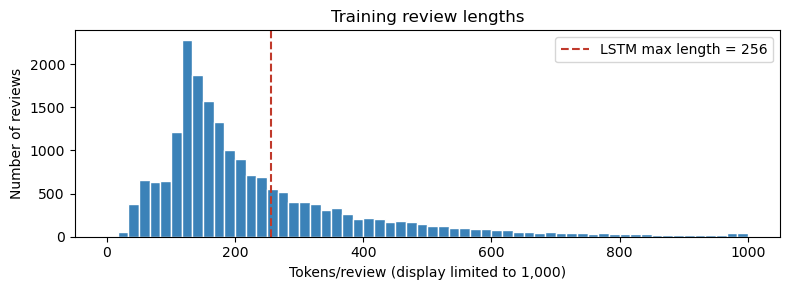

In [ ]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip().lower()


TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[0-9]+")


def tokenize(text):
    return TOKEN_RE.findall(text)


for frame in frames.values():
    frame["clean"] = frame.text.map(clean_text)
    frame["digest"] = frame.clean.map(lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest())

digest_sets = {name: set(frame.digest) for name, frame in frames.items()}
duplicate_audit = {
    "train_validation_shared_unique_texts": len(digest_sets["train"] & digest_sets["validation"]),
    "train_test_shared_unique_texts": len(digest_sets["train"] & digest_sets["test"]),
    "validation_test_shared_unique_texts": len(digest_sets["validation"] & digest_sets["test"]),
}
print("Trùng văn bản sau làm sạch:", duplicate_audit)
train_lengths = train.clean.map(lambda s: len(tokenize(s)))
display(train_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("train token count"))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(train_lengths, bins=60, range=(0, 1000), color="#3b82b8", edgecolor="white")
ax.axvline(256, color="#c0392b", linestyle="--", label="LSTM max length = 256")
ax.set(xlabel="Tokens/review (display limited to 1,000)", ylabel="Number of reviews", title="Training review lengths")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "length_distribution.png", dpi=150)
plt.show()

## 3. Logistic Regression và SVM

Biểu diễn TF-IDF sử dụng unigram/bigram, tối đa **25.000 đặc trưng**, `min_df=2`,
`sublinear_tf=True` và chuẩn hóa L2. Chọn `C ∈ {0.5, 1, 2}` theo **F1 validation**
cho Logistic Regression và SVM tuyến tính.

Validation và test chỉ được biến đổi bằng TF-IDF đã fit trên train. Không refit
với validation để cả bốn mô hình đều học trọng số từ cùng 20.000 mẫu.

In [ ]:
feature_start = time.perf_counter()
vectorizer = TfidfVectorizer(max_features=25_000, ngram_range=(1, 2), min_df=2,
                             sublinear_tf=True, dtype=np.float32)
X_train = vectorizer.fit_transform(train.clean)
X_valid = vectorizer.transform(valid.clean)
tfidf_seconds = time.perf_counter() - feature_start
y_train = train.label.to_numpy(dtype=np.int64)
y_valid = valid.label.to_numpy(dtype=np.int64)
y_test = test.label.to_numpy(dtype=np.int64)
print("TF-IDF train:", X_train.shape, "nonzero:", X_train.nnz)
print(f"Fit + transform train/validation: {tfidf_seconds:.2f}s")

classical_models = {}
selection_rows = []
training_info = {}
for name, model_class in [("Logistic Regression", LogisticRegression), ("Linear SVM", LinearSVC)]:
    start = time.perf_counter()
    best_f1 = -1
    for c in [0.5, 1.0, 2.0]:
        if name == "Logistic Regression":
            model = model_class(C=c, max_iter=1000, solver="liblinear", random_state=SEED)
        else:
            model = model_class(C=c, max_iter=5000, dual="auto", random_state=SEED)
        fit_start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - fit_start
        pred = model.predict(X_valid)
        score = f1_score(y_valid, pred)
        selection_rows.append({"model": name, "C": c, "validation_f1": score,
                               "validation_accuracy": accuracy_score(y_valid, pred),
                               "fit_seconds": fit_seconds})
        if score > best_f1:
            best_f1 = score
            classical_models[name] = model
            training_info[name] = {"C": c, "validation_f1": score, "selected_fit_seconds": fit_seconds}
    training_info[name]["training_selection_seconds"] = time.perf_counter() - start
    print(name, training_info[name], flush=True)
selection_table = pd.DataFrame(selection_rows)
selection_table.to_csv(OUT / "classical_validation.csv", index=False)
display(selection_table)

TF-IDF train: (20000, 25000) nonzero: 4355866
Fit + transform train/validation: 11.39s


Logistic Regression {'C': 2.0, 'validation_f1': 0.9038155802861685, 'selected_fit_seconds': 0.5882806999998138, 'training_selection_seconds': 1.4045922000004794}


Linear SVM {'C': 0.5, 'validation_f1': 0.9067678179277301, 'selected_fit_seconds': 0.4211517999992793, 'training_selection_seconds': 1.6191262000011193}


,model,C,validation_f1,validation_accuracy,fit_seconds
0,Logistic Regression,0.5,0.894006,0.8932,0.392256
1,Logistic Regression,1.0,0.899662,0.8990,0.408003
2,Logistic Regression,2.0,0.903816,0.9032,0.588281
3,Linear SVM,0.5,0.906768,0.9066,0.421152
4,Linear SVM,1.0,0.904230,0.9040,0.524247
5,Linear SVM,2.0,0.899119,0.8992,0.657189


## 4. Mạng neural cơ bản: MLP

**TF-IDF → Dense(64) → ReLU → Dropout(0.5) → Dense(1)**.

Huấn luyện bằng Adam, learning rate 0.001, batch 128 và `BCEWithLogitsLoss`.
Giới hạn 15 epoch, early stopping với patience 3; khôi phục checkpoint có
validation loss thấp nhất. Ma trận TF-IDF được chuyển sang dense theo từng batch.

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(),
                                    nn.Dropout(0.5), nn.Linear(64, 1))

    def forward(self, x):
        return self.layers(x).squeeze(1)


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def train_neural(model, make_batches, max_epochs, patience, checkpoint_name, lr=0.001):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    history = []
    best_loss, best_epoch, stale = float("inf"), 0, 0
    best_state = None
    sync_device()
    start = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        epoch_start = time.perf_counter()
        record = {"epoch": epoch}
        for phase in ["train", "validation"]:
            model.train(phase == "train")
            loss_sum, correct, count = 0.0, 0, 0
            with torch.set_grad_enabled(phase == "train"):
                for inputs, labels in make_batches(phase, shuffle=(phase == "train")):
                    inputs = [item.to(DEVICE) for item in inputs]
                    labels = labels.to(DEVICE).float()
                    if phase == "train":
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(*inputs)
                    loss = criterion(logits, labels)
                    if phase == "train":
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        optimizer.step()
                    n = len(labels)
                    loss_sum += loss.item() * n
                    correct += ((logits >= 0) == labels.bool()).sum().item()
                    count += n
            record[f"{phase}_loss"] = loss_sum / count
            record[f"{phase}_accuracy"] = correct / count
        sync_device()
        record["seconds"] = time.perf_counter() - epoch_start
        history.append(record)
        print(f"{checkpoint_name} epoch {epoch}: train loss={record['train_loss']:.4f}, "
              f"val loss={record['validation_loss']:.4f}, val acc={record['validation_accuracy']:.4f}, "
              f"{record['seconds']:.1f}s", flush=True)
        if record["validation_loss"] < best_loss - 1e-4:
            best_loss, best_epoch, stale = record["validation_loss"], epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        if stale >= patience:
            print("Early stopping; restore epoch", best_epoch, flush=True)
            break
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{checkpoint_name}.pt")
    pd.DataFrame(history).to_csv(OUT / f"{checkpoint_name}_history.csv", index=False)
    return model, history, {"training_selection_seconds": elapsed,
                            "best_epoch": best_epoch, "epochs_run": len(history),
                            "best_validation_loss": best_loss}


BATCH_SIZE = 128


def dense_batches(matrix, labels, shuffle=False):
    indices = np.random.permutation(len(labels)) if shuffle else np.arange(len(labels))
    for start in range(0, len(indices), BATCH_SIZE):
        idx = indices[start:start + BATCH_SIZE]
        yield [torch.from_numpy(matrix[idx].toarray())], torch.from_numpy(labels[idx])


def mlp_batches(phase, shuffle=False):
    matrix, labels = (X_train, y_train) if phase == "train" else (X_valid, y_valid)
    yield from dense_batches(matrix, labels, shuffle)


seed_everything()
mlp, mlp_history, training_info["MLP"] = train_neural(
    MLP(X_train.shape[1]), mlp_batches, max_epochs=15, patience=3, checkpoint_name="mlp")

mlp epoch 1: train loss=0.5510, val loss=0.3722, val acc=0.8836, 2.0s


mlp epoch 2: train loss=0.2785, val loss=0.2536, val acc=0.9052, 1.6s


mlp epoch 3: train loss=0.1809, val loss=0.2260, val acc=0.9084, 1.5s


mlp epoch 4: train loss=0.1239, val loss=0.2186, val acc=0.9114, 1.5s


mlp epoch 5: train loss=0.0883, val loss=0.2205, val acc=0.9088, 1.5s


mlp epoch 6: train loss=0.0629, val loss=0.2264, val acc=0.9086, 1.5s


mlp epoch 7: train loss=0.0454, val loss=0.2337, val acc=0.9072, 1.6s


Early stopping; restore epoch 4


## 5. LSTM

Từ vựng gồm tối đa **20.000 token**, với PAD=0 và UNK=1, được xây dựng từ train.
Mỗi bình luận giữ **256 token đầu**, padding phía phải. Bộ tách từ giữ từ tiếng Anh,
số và dấu nháy trong từ.

**Embedding(128) → LSTM một chiều(128) → masked mean/max pooling → Dropout(0.5) → Dense(1)**.

Embedding học từ đầu, có dropout 0.2 ở đầu vào. Pooling chỉ tổng hợp trạng thái
của token hợp lệ. Các cổng của LSTM điều khiển cập nhật bộ nhớ để học phụ thuộc
trong chuỗi.

Adam, learning rate 0.001, batch 128, `BCEWithLogitsLoss` và gradient clipping
norm 1.0. Giới hạn 8 epoch, patience 2; chọn checkpoint theo validation loss.

In [ ]:
sequence_start = time.perf_counter()
MAX_VOCAB = 20_000
MAX_LENGTH = 256
EMBED_DIM = 128
HIDDEN_DIM = 128
counts = Counter(token for text in train.clean for token in tokenize(text))
vocab = {"<PAD>": 0, "<UNK>": 1}
vocab.update({word: i + 2 for i, (word, _) in enumerate(counts.most_common(MAX_VOCAB - 2))})


def encode_texts(texts):
    ids = np.zeros((len(texts), MAX_LENGTH), dtype=np.int64)
    lengths = np.ones(len(texts), dtype=np.int64)
    for i, text in enumerate(texts):
        tokens = tokenize(text)[:MAX_LENGTH]
        encoded = [vocab.get(token, 1) for token in tokens] or [1]
        ids[i, :len(encoded)] = encoded
        lengths[i] = len(encoded)
    return ids, lengths


train_ids, train_lens = encode_texts(train.clean.tolist())
valid_ids, valid_lens = encode_texts(valid.clean.tolist())
sequence_seconds = time.perf_counter() - sequence_start
truncated_fraction = float((train_lengths > MAX_LENGTH).mean())
print(f"Vocabulary: {len(vocab):,}; train reviews truncated: {truncated_fraction:.2%}")
print(f"Vocabulary + encode train/validation: {sequence_seconds:.2f}s")


def sequence_batches(ids, lengths, labels, shuffle=False):
    indices = np.random.permutation(len(labels)) if shuffle else np.arange(len(labels))
    for start in range(0, len(indices), BATCH_SIZE):
        idx = indices[start:start + BATCH_SIZE]

        width = int(lengths[idx].max())
        yield [torch.from_numpy(ids[idx, :width]), torch.from_numpy(lengths[idx])], torch.from_numpy(labels[idx])


def lstm_batches(phase, shuffle=False):
    ids, lens, labels = ((train_ids, train_lens, y_train) if phase == "train"
                         else (valid_ids, valid_lens, y_valid))
    yield from sequence_batches(ids, lens, labels, shuffle)


class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.input_dropout = nn.Dropout(0.2)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.output = nn.Sequential(nn.Dropout(0.5), nn.Linear(hidden_dim * 2, 1))

    def forward(self, ids, lengths):
        embeddings = self.input_dropout(self.embedding(ids))
        states, _ = self.lstm(embeddings)
        mask = torch.arange(ids.shape[1], device=ids.device)[None, :] < lengths[:, None]
        mean_pool = (states * mask.unsqueeze(-1)).sum(1) / lengths.unsqueeze(1)
        max_pool = states.masked_fill(~mask.unsqueeze(-1), float("-inf")).amax(1)
        return self.output(torch.cat([mean_pool, max_pool], dim=1)).squeeze(1)


seed_everything()
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
lstm, lstm_history, training_info["LSTM"] = train_neural(
    SentimentLSTM(len(vocab)), lstm_batches, max_epochs=8, patience=2, checkpoint_name="lstm")
lstm_peak_mb = torch.cuda.max_memory_allocated() / 1024**2 if DEVICE.type == "cuda" else None
print("LSTM trainable parameters:", sum(p.numel() for p in lstm.parameters() if p.requires_grad))
if lstm_peak_mb is not None:
    print(f"Peak CUDA tensor memory: {lstm_peak_mb:.1f} MiB (excludes driver/runtime allocations)")

Vocabulary: 20,000; train reviews truncated: 29.05%
Vocabulary + encode train/validation: 3.35s


lstm epoch 1: train loss=0.6184, val loss=0.5367, val acc=0.7350, 2.6s


lstm epoch 2: train loss=0.4309, val loss=0.3785, val acc=0.8276, 2.1s


lstm epoch 3: train loss=0.3440, val loss=0.3903, val acc=0.8472, 2.1s


lstm epoch 4: train loss=0.2884, val loss=0.3109, val acc=0.8664, 2.1s


lstm epoch 5: train loss=0.2471, val loss=0.3039, val acc=0.8746, 2.1s


lstm epoch 6: train loss=0.2151, val loss=0.3381, val acc=0.8724, 2.1s


lstm epoch 7: train loss=0.1852, val loss=0.3271, val acc=0.8754, 2.1s


Early stopping; restore epoch 5


LSTM trainable parameters: 2692353
Peak CUDA tensor memory: 602.9 MiB (excludes driver/runtime allocations)


## 6. Đánh giá trên tập test

Đánh giá các mô hình đã chọn bằng **Accuracy, Precision, Recall và F1**;
Precision/Recall/F1 tính cho lớp positive. Ngưỡng quyết định là 0 cho SVM decision
score và 0.5 cho đầu ra sigmoid.

Thời gian huấn luyện bao gồm validation để chọn cấu hình hoặc checkpoint,
không gồm tải dữ liệu và tiền xử lý. Thời gian dự đoán được đo riêng.
Ngân sách chọn cấu hình khác nhau giữa các mô hình nên thời gian chỉ phản ánh
thiết lập thực nghiệm này.

In [ ]:
@torch.inference_mode()
def neural_scores(model, batches):
    model.eval()
    outputs = []
    for inputs, _ in batches:
        logits = model(*[item.to(DEVICE) for item in inputs])
        outputs.append(logits.cpu().numpy())
    return np.concatenate(outputs)


X_test = vectorizer.transform(test.clean)
test_ids, test_lens = encode_texts(test.clean.tolist())
scores, predictions = {}, {}
metrics_rows = []
for name in ["Logistic Regression", "Linear SVM", "MLP", "LSTM"]:
    sync_device()
    start = time.perf_counter()
    if name in classical_models:
        scores[name] = classical_models[name].decision_function(X_test)
    elif name == "MLP":
        scores[name] = neural_scores(mlp, dense_batches(X_test, y_test))
    else:
        scores[name] = neural_scores(lstm, sequence_batches(test_ids, test_lens, y_test))
    sync_device()
    predict_seconds = time.perf_counter() - start
    predictions[name] = (scores[name] >= 0).astype(np.int64)
    pred = predictions[name]
    metrics_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                         "precision": precision_score(y_test, pred, zero_division=0),
                         "recall": recall_score(y_test, pred, zero_division=0),
                         "f1": f1_score(y_test, pred, zero_division=0),
                         "training_selection_seconds": training_info[name]["training_selection_seconds"],
                         "test_predict_seconds": predict_seconds})
    report = classification_report(y_test, pred, target_names=["negative", "positive"], output_dict=True)
    (OUT / (name.lower().replace(" ", "_") + "_classification_report.json")).write_text(
        json.dumps(report, indent=2), encoding="utf-8")

results = pd.DataFrame(metrics_rows).set_index("model")
results.to_csv(OUT / "results.csv")
display(results.round(4))
predictions_frame = test[["id", "label"]].copy()
for name in predictions:
    key = name.lower().replace(" ", "_")
    predictions_frame[f"{key}_prediction"] = predictions[name]
    predictions_frame[f"{key}_decision_score"] = scores[name]
predictions_frame.to_csv(OUT / "test_predictions.csv", index=False)

,accuracy,precision,recall,f1,training_selection_seconds,test_predict_seconds
model,,,,,,
Logistic Regression,0.8988,0.8956,0.9028,0.8992,1.4046,0.0200
Linear SVM,0.8964,0.8956,0.8974,0.8965,1.6191,0.0224
MLP,0.9019,0.8948,0.9109,0.9028,11.1793,1.7432
LSTM,0.8622,0.8524,0.8762,0.8641,15.2086,0.9786


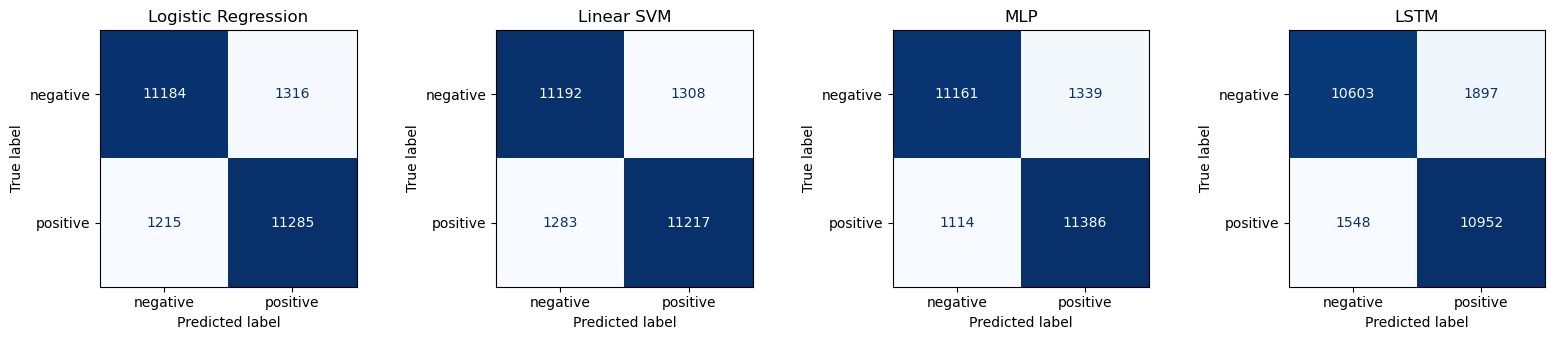

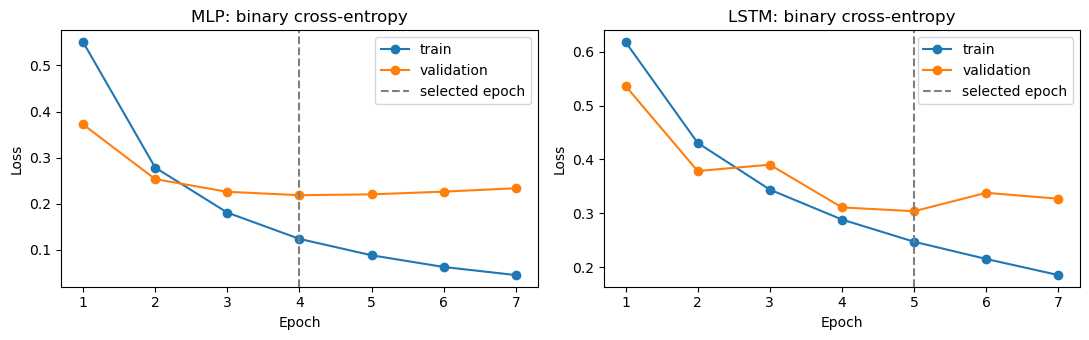

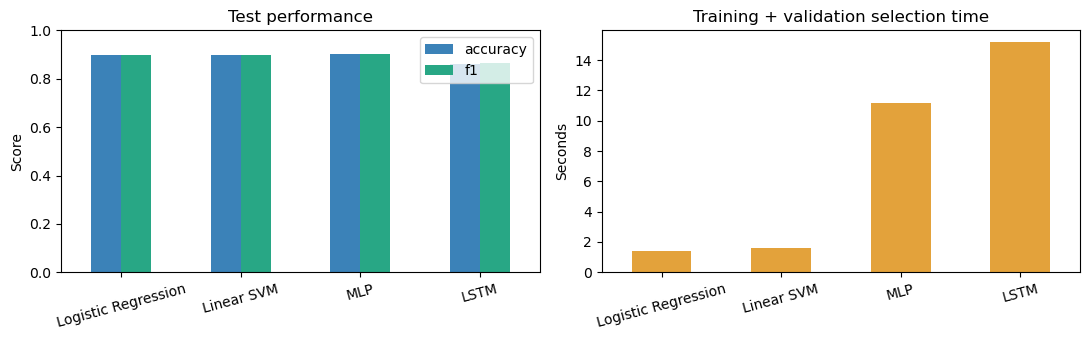

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, predictions):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions[name]),
                           display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, history) in zip(axes, [("MLP", mlp_history), ("LSTM", lstm_history)]):
    h = pd.DataFrame(history)
    ax.plot(h.epoch, h.train_loss, marker="o", label="train")
    ax.plot(h.epoch, h.validation_loss, marker="o", label="validation")
    ax.axvline(training_info[name]["best_epoch"], linestyle="--", color="gray", label="selected epoch")
    ax.set(title=f"{name}: binary cross-entropy", xlabel="Epoch", ylabel="Loss")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "learning_curves.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
results[["accuracy", "f1"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=15, color=["#3b82b8", "#28a785"])
axes[0].set(title="Test performance", ylabel="Score", xlabel="")
results.training_selection_seconds.plot.bar(ax=axes[1], color="#e3a23b", rot=15)
axes[1].set(title="Training + validation selection time", ylabel="Seconds", xlabel="")
fig.tight_layout()
fig.savefig(OUT / "comparison.png", dpi=150)
plt.show()

## 7. Phân tích lỗi

Khảo sát false positive và false negative của LSTM; so sánh kết quả giữa bình luận
**≤256 token** và **>256 token** để xem xét ảnh hưởng có thể có của cắt chuỗi.
Điểm sigmoid chưa được hiệu chỉnh xác suất. Các phân tích được thực hiện sau
đánh giá và không dùng để điều chỉnh mô hình.

In [ ]:
error_rows = []
for true_label in [0, 1]:
    indices = np.flatnonzero((y_test == true_label) & (predictions["LSTM"] != y_test))[:4]
    for i in indices:
        error_rows.append({"id": test.iloc[i].id, "true": int(y_test[i]),
                           "predicted": int(predictions["LSTM"][i]),
                           "positive_sigmoid": float(expit(scores["LSTM"][i])),
                           "token_count": len(tokenize(test.iloc[i].clean)),
                           "excerpt": test.iloc[i].clean[:600]})
errors = pd.DataFrame(error_rows)
errors.to_csv(OUT / "lstm_error_examples.csv", index=False)
with pd.option_context("display.max_colwidth", 180):
    display(errors)

test_lengths = test.clean.map(lambda s: len(tokenize(s))).to_numpy()
length_rows = []
for group, mask in [("<=256 tokens", test_lengths <= MAX_LENGTH), (">256 tokens", test_lengths > MAX_LENGTH)]:
    for name, pred in predictions.items():
        length_rows.append({"length_group": group, "model": name, "n": int(mask.sum()),
                            "accuracy": accuracy_score(y_test[mask], pred[mask]),
                            "f1": f1_score(y_test[mask], pred[mask], zero_division=0)})
length_results = pd.DataFrame(length_rows)
length_results.to_csv(OUT / "results_by_length.csv", index=False)
display(length_results.round(4))

,id,true,predicted,positive_sigmoid,token_count,excerpt
0,test/00011,0,1,0.711753,191,"blind date (columbia pictures, 1934), was a decent film, but i have a few issues with this film. first of all, i don't fault the actors in this film at all, but more or less, i..."
1,test/00018,0,1,0.918802,251,"ben, (rupert grint), is a deeply unhappy adolescent, the son of his unhappily married parents. his father, (nicholas farrell), is a vicar and his mother, (laura linney), is ......"
2,test/00029,0,1,0.624652,71,"never ever take a film just for its good looking title. although it all starts well, the film suffers the same imperfections you see in b-films. its like at a certain moment th..."
3,test/00032,0,1,0.556889,398,"i'm the type of guy who loves hood movies from new jack city to baby boy to killa season, from the b grade to the hollywood. but this movie was something different. i am no hat..."
4,test/12501,1,0,0.486911,366,"contains ""spoiler"" information. watch this director's other film, ""earth"", at some point. it's a better film, but this one isn't bad just different. a rare feminist point of vi..."
5,test/12508,1,0,0.295676,495,"i finally watched the third film in mehta's trilogy: ""fire"". to begin, i'd say that ""water"" was the unquestionable masterpiece, on all levels. fire comes next with earth close ..."
6,test/12514,1,0,0.042309,112,this was a bold movie to hit indian cinemas when it was released. the first movie to perhaps openly depict lesbian tendencies amongst indian women. the leading actress of india...
7,test/12518,1,0,0.354643,47,the theme is controversial and the depiction of the hypocritical and sexually starved india is excellent.nothing more to this film.there is a lack of good dialogues(why was the...


,length_group,model,n,accuracy,f1
0,<=256 tokens,Logistic Regression,18008,0.8985,0.8993
1,<=256 tokens,Linear SVM,18008,0.8966,0.8972
2,<=256 tokens,MLP,18008,0.9023,0.9035
3,<=256 tokens,LSTM,18008,0.8749,0.8768
4,>256 tokens,Logistic Regression,6992,0.8995,0.8987
5,>256 tokens,Linear SVM,6992,0.8957,0.8944
6,>256 tokens,MLP,6992,0.9007,0.9009
7,>256 tokens,LSTM,6992,0.8295,0.8311


### Một số trường hợp dự đoán sai

| Mẫu | Nhãn thật → dự đoán | Nhận xét |
|---|---|---|
| `test/00011` | Negative → Positive | Khen diễn viên và giá trị sản xuất nhưng chê kịch bản. Cảm xúc pha trộn; chỉ 191 token nên không bị cắt chuỗi. |
| `test/00029` | Negative → Positive | Khen phần mở đầu nhưng chê cách kết thúc và đánh giá tổng thể tiêu cực. Bình luận dài 71 token, cho thấy khó khăn khi diễn giải chuyển ý. |
| `test/12501` | Positive → Negative | Phần lớn nội dung tóm tắt xung đột, phần cuối khen cách xây dựng nhân vật. Dài 366 token nên LSTM mất phần cuối. |
| `test/12518` | Positive → Negative | Khen chủ đề nhưng chê thoại và diễn xuất; nhãn positive vẫn chứa nhiều nhận xét tiêu cực. |

Các mẫu được lấy theo thứ tự dữ liệu. Diễn giải dựa trên nội dung bình luận;
chưa có thí nghiệm đối chứng để xác nhận nguyên nhân của từng lỗi.

## 8. Lưu mô hình và dự đoán bình luận mới

Lưu TF-IDF, từ vựng, cấu hình và trọng số của các mô hình; minh họa dự đoán
trên ba bình luận tiếng Anh.

In [ ]:
joblib.dump(vectorizer, OUT / "tfidf.joblib")
joblib.dump(classical_models, OUT / "classical_models.joblib")
config = {"max_vocab": MAX_VOCAB, "actual_vocab": len(vocab), "max_length": MAX_LENGTH,
          "embedding_dim": EMBED_DIM, "hidden_dim": HIDDEN_DIM, "batch_size": BATCH_SIZE,
          "mlp_hidden_dim": 64, "mlp_dropout": 0.5, "lstm_input_dropout": 0.2,
          "lstm_output_dropout": 0.5, "learning_rate": 0.001, "seed": SEED,
          "tfidf_features": X_train.shape[1], "threshold_logit": 0.0,
          "training_info": training_info, "duplicate_audit": duplicate_audit,
          "train_truncated_fraction": truncated_fraction,
          "tfidf_train_validation_seconds": tfidf_seconds,
          "sequence_train_validation_seconds": sequence_seconds,
          "lstm_peak_cuda_tensor_mb": lstm_peak_mb}
(OUT / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(OUT / "vocabulary.json").write_text(json.dumps(vocab, ensure_ascii=False), encoding="utf-8")


def predict_reviews(texts):
    cleaned = [clean_text(text) for text in texts]
    features = vectorizer.transform(cleaned)
    ids, lengths = encode_texts(cleaned)
    dummy_labels = np.zeros(len(texts), dtype=np.int64)
    output = pd.DataFrame({"text": texts})
    for name, model in classical_models.items():
        output[name] = np.where(model.predict(features) == 1, "positive", "negative")
    for name, model, batches in [
        ("MLP", mlp, dense_batches(features, dummy_labels)),
        ("LSTM", lstm, sequence_batches(ids, lengths, dummy_labels)),
    ]:
        logits = neural_scores(model, batches)
        output[name] = np.where(logits >= 0, "positive", "negative")
    return output


display(predict_reviews([
    "A wonderful movie with great acting. I really enjoyed it.",
    "The plot was boring and the acting was terrible. A waste of time.",
    "I did not like this movie at all.",
]))

,text,Logistic Regression,Linear SVM,MLP,LSTM
0,A wonderful movie with great acting. I really ...,positive,positive,positive,positive
1,The plot was boring and the acting was terribl...,negative,negative,negative,negative
2,I did not like this movie at all.,negative,negative,negative,negative


## 9. Kết luận

Tổng hợp kết quả, chi phí huấn luyện và các giới hạn của thực nghiệm.

In [ ]:
winner = results.f1.idxmax()
lstm_acc = results.loc["LSTM", "accuracy"]
lstm_f1 = results.loc["LSTM", "f1"]
svm_f1 = results.loc["Linear SVM", "f1"]
gap = (lstm_f1 - svm_f1) * 100
table_lines = ["| Mô hình | Accuracy | Precision | Recall | F1 | Train + chọn cấu hình (s) |",
               "|---|---:|---:|---:|---:|---:|"]
for name, row in results.iterrows():
    table_lines.append(f"| {name} | {row.accuracy:.4f} | {row.precision:.4f} | {row.recall:.4f} | "
                       f"{row.f1:.4f} | {row.training_selection_seconds:.1f} |")
comparison_table = "\n".join(table_lines)
interpretation = (
    "TF-IDF + SVM có F1 cao hơn LSTM trong lần chạy này. Một giải thích có thể là các "
    "unigram/bigram chứa tín hiệu cảm xúc mạnh, SVM dùng toàn bộ văn bản trong khi LSTM "
    "chỉ dùng 256 token đầu và phải học embedding từ đầu. Đây là giả thuyết giải thích, "
    "chưa phải kết luận nhân quả vì chưa chạy ablation."
    if gap < 0 else
    "LSTM có F1 bằng hoặc cao hơn SVM trong lần chạy này. Khả năng học biểu diễn theo "
    "ngữ cảnh có thể có ích, nhưng thí nghiệm này chưa tách riêng ảnh hưởng của kiến trúc, "
    "biểu diễn đầu vào và cấu hình huấn luyện."
)
conclusion = f"""### Nhận xét

- Mô hình có F1 test cao nhất trong cấu hình đã thử: **{winner}**, F1 **{results.loc[winner, 'f1']:.4f}**.
- LSTM đạt Accuracy **{lstm_acc:.4f}**, F1 **{lstm_f1:.4f}**; chênh lệch F1 so với SVM là **{gap:+.2f} điểm phần trăm**.
- {interpretation}
- MLP chọn epoch **{training_info['MLP']['best_epoch']}**, LSTM chọn epoch **{training_info['LSTM']['best_epoch']}** theo validation loss. Nếu train loss giảm nhưng validation loss tăng, đó là dấu hiệu quá khớp; checkpoint và early stopping hạn chế ảnh hưởng này.
- **{truncated_fraction:.1%}** bình luận train dài hơn 256 token, bị cắt ở nhánh LSTM; nhánh TF-IDF không có giới hạn 256 token.
- Kiểm tra trùng lặp sau làm sạch: **{duplicate_audit}**. Các văn bản trùng có thể làm ước lượng khả năng tổng quát lạc quan hơn; kết quả vẫn dùng nguyên split chính thức để đối chiếu.
- Thời gian được đo trên **{environment['gpu'] or 'CPU'}**, batch 128. Bộ nhớ CUDA tensor cực đại ghi trong `artifacts/config.json`; số này không bao gồm toàn bộ bộ nhớ driver/runtime.
- Giới hạn: một seed, một split validation, ngân sách tuning nhỏ và biểu diễn khác nhau giữa các nhánh. Chưa báo cáo độ biến thiên nhiều seed hoặc kiểm định ý nghĩa thống kê; không diễn giải chênh lệch nhỏ như kết luận chắc chắn.
- Hướng mở rộng: nhiều seed; thử độ dài 128/256/512; embedding pretrained hoặc BiLSTM/GRU; dùng cùng ngân sách tuning. Chỉ chọn thay đổi bằng validation và dùng một tập kiểm tra mới nếu đã điều chỉnh dựa trên phân tích test này.
"""
display(Markdown(conclusion))
report_text = f"""# Báo cáo: Phân tích cảm xúc IMDB

Họ tên / MSSV / lớp: ................................

## Bài toán và dữ liệu

Phân loại negative (0) / positive (1), bộ IMDB Stanford 50.000 mẫu có nhãn.
Chọn LSTM theo yêu cầu chỉ cần một trong RNN/LSTM/GRU; so sánh với MLP,
Logistic Regression và SVM. Split: 20.000 train, 5.000 validation, 25.000 test,
seed 42, chia phân tầng từ train chính thức. Không dùng dữ liệu không nhãn.
Nguồn tải: repository chính thức `stanfordnlp/imdb`, revision `{REVISION}`.
SHA-256 từng file: xem `artifacts/data_source.json`.

## Phương pháp

Làm sạch HTML, chữ thường, chuẩn hóa khoảng trắng, giữ phủ định.
TF-IDF unigram/bigram tối đa 25.000 đặc trưng, min_df=2, sublinear_tf=True.
Logistic Regression và LinearSVC thử C=0.5/1/2, chọn bằng F1 validation.
MLP: TF-IDF → Dense64/ReLU/Dropout0.5 → logit.
LSTM: từ vựng train tối đa 20.000, 256 token đầu, Embedding128 → LSTM128 →
masked mean/max pooling → Dropout0.5 → logit. Embedding học từ đầu.
Hai mạng dùng BCEWithLogitsLoss, Adam lr=0.001, batch128, clip norm1.0;
MLP tối đa15 epoch/patience3, LSTM tối đa8 epoch/patience2.
Chọn checkpoint theo validation loss; không refit validation; không tuning trên test.

## Kết quả

{comparison_table}

Precision/Recall/F1 tính cho lớp positive; quyết định sigmoid tại 0.5,
SVM tại decision score 0. Thời gian gồm train và validation chọn cấu hình,
không gồm tải/tiền xử lý. TF-IDF train/validation: {tfidf_seconds:.2f}s;
tạo từ vựng và encode train/validation: {sequence_seconds:.2f}s.
Tốc độ các nhánh chịu ảnh hưởng của ngân sách tuning và biểu diễn khác nhau.

![So sánh](artifacts/comparison.png)
![Confusion matrices](artifacts/confusion_matrices.png)
![Learning curves](artifacts/learning_curves.png)

{conclusion}

## Phân tích lỗi

Xem `artifacts/lstm_error_examples.csv` (4 false positive, 4 false negative nếu đủ),
`artifacts/results_by_length.csv` và mục 7 của notebook. Các lỗi có thể liên quan
đến cảm xúc pha trộn, phủ định, mỉa mai và cắt chuỗi; cần đọc toàn bộ bình luận để
xác nhận từng nguyên nhân, không thể suy ra chắc chắn chỉ từ nhãn sai.

## Tái lập

Xem README.md, notebook và `artifacts/environment.json`, `config.json`,
`split_manifest.csv`. Các kết quả đều đo từ lần chạy thực tế của notebook.

## Tài liệu tham khảo

1. Maas et al. (2011), Learning Word Vectors for Sentiment Analysis. https://aclanthology.org/P11-1015/
2. Stanford Large Movie Review Dataset. https://ai.stanford.edu/~amaas/data/sentiment/
3. Hochreiter & Schmidhuber (1997), Long Short-Term Memory. https://doi.org/10.1162/neco.1997.9.8.1735
4. PyTorch LSTM. https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html
5. Scikit-learn text feature extraction. https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
6. Speech and Language Processing, bản 3rd edition draft và tài liệu Stanford NLP theo slide môn học (số chương có thể khác giữa các bản draft).
"""
(ROOT / "REPORT.md").write_text(report_text, encoding="utf-8")
print("Đã lưu REPORT.md, mô hình, biểu đồ và kết quả trong artifacts/.")

### Nhận xét

- Mô hình có F1 test cao nhất trong cấu hình đã thử: **MLP**, F1 **0.9028**.
- LSTM đạt Accuracy **0.8622**, F1 **0.8641**; chênh lệch F1 so với SVM là **-3.24 điểm phần trăm**.
- TF-IDF + SVM có F1 cao hơn LSTM trong lần chạy này. Một giải thích có thể là các unigram/bigram chứa tín hiệu cảm xúc mạnh, SVM dùng toàn bộ văn bản trong khi LSTM chỉ dùng 256 token đầu và phải học embedding từ đầu. Đây là giả thuyết giải thích, chưa phải kết luận nhân quả vì chưa chạy ablation.
- MLP chọn epoch **4**, LSTM chọn epoch **5** theo validation loss. Nếu train loss giảm nhưng validation loss tăng, đó là dấu hiệu quá khớp; checkpoint và early stopping hạn chế ảnh hưởng này.
- **29.1%** bình luận train dài hơn 256 token, bị cắt ở nhánh LSTM; nhánh TF-IDF không có giới hạn 256 token.
- Kiểm tra trùng lặp sau làm sạch: **{'train_validation_shared_unique_texts': 35, 'train_test_shared_unique_texts': 99, 'validation_test_shared_unique_texts': 24}**. Các văn bản trùng có thể làm ước lượng khả năng tổng quát lạc quan hơn; kết quả vẫn dùng nguyên split chính thức để đối chiếu.
- Thời gian được đo trên **NVIDIA GeForce RTX 4050 Laptop GPU**, batch 128. Bộ nhớ CUDA tensor cực đại ghi trong `artifacts/config.json`; số này không bao gồm toàn bộ bộ nhớ driver/runtime.
- Giới hạn: một seed, một split validation, ngân sách tuning nhỏ và biểu diễn khác nhau giữa các nhánh. Chưa báo cáo độ biến thiên nhiều seed hoặc kiểm định ý nghĩa thống kê; không diễn giải chênh lệch nhỏ như kết luận chắc chắn.
- Hướng mở rộng: nhiều seed; thử độ dài 128/256/512; embedding pretrained hoặc BiLSTM/GRU; dùng cùng ngân sách tuning. Chỉ chọn thay đổi bằng validation và dùng một tập kiểm tra mới nếu đã điều chỉnh dựa trên phân tích test này.


Đã lưu REPORT.md, mô hình, biểu đồ và kết quả trong artifacts/.


## Tài liệu tham khảo

1. [Maas et al. (2011), Learning Word Vectors for Sentiment Analysis](https://aclanthology.org/P11-1015/).
2. [Stanford NLP — IMDB dataset](https://huggingface.co/datasets/stanfordnlp/imdb).
3. [Hochreiter & Schmidhuber (1997), Long Short-Term Memory](https://doi.org/10.1162/neco.1997.9.8.1735).
4. [PyTorch — LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).
5. [Scikit-learn — Text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction).
6. Speech and Language Processing (3rd ed. draft), phần RNN/LSTM và slide môn học.